<a href="https://colab.research.google.com/github/saraeastough/SCI1500-Sara-Eastough-public/blob/main/SCIE1500Materials/Week_12/LabFiles/Week12_Lab_STUDENT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 12 Lab — Linear Programming
**SCIE1500 — Analytical Methods for Scientists (UWA)**

**Lab format:** Warmup — shared LP (35 min) → Your assigned LP problem (45 min) → Class discussion & instructor confirmation (15 min) → Debrief (5 min)

---
**Today:** We solve linear programming (LP) problems — optimisation models with a linear objective and linear constraints. Everyone works through the same warmup problem first. Then each group is assigned one LP scenario from the appendix and works through it in full, including a sensitivity analysis. We finish with a whole-class discussion where your demonstrator confirms each group's solution and highlights common errors.

---
## 🔥 Warmup Scenario (Everyone)

![Linear programming feasible region with constraint lines](https://github.com/ahailu95/scie1500-content/blob/main/SCIE1500Materials/Week_12/images/W12_linear_programming.svg?raw=1)

A hospital dietitian needs to design a daily meal plan for patients that meets nutritional requirements at minimum cost. Two food types are available:

- **Food X** (plant-based): costs **$2.50/serve**, provides 18 g protein, 220 kcal, 3 mg iron, 0.5 kg CO₂-e
- **Food Y** (chicken): costs **$4.00/serve**, provides 30 g protein, 280 kcal, 1 mg iron, 2.5 kg CO₂-e

Daily requirements per patient:
- Protein: at least 350 g
- Calories: at least 3,500 kcal
- Iron: at least 25 mg
- Carbon footprint: at most 20 kg CO₂-e per day

**Decision variables:** $x$ = serves of Food X, $y$ = serves of Food Y

Work through Parts 1–3 below as a group. This warmup uses the same LP workflow (formulate → graph → corner points) that you will apply to your own assigned LP problem in Part 4.

---
## 🎯 Warmup Task

| Part | Topic | Time |
|------|-------|------|
| 1 | Formulate the LP and identify constraints | ~10 min |
| 2 | Graph the feasible region | ~15 min |
| 3 | Find the optimal solution using corner-point theorem | ~10 min |

In [1]:
# Run this cell first — loads libraries for today's lab
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

# LP parameters
cost = np.array([2.5, 4.0])     # objective: minimise 2.5x + 4y

# Constraints (as functions of x for plotting y = f(x))
def protein_line(x):
    '18x + 30y = 350  →  y = (350 - 18x) / 30'
    return (350 - 18*x) / 30

def calorie_line(x):
    '220x + 280y = 3500  →  y = (3500 - 220x) / 280'
    return (3500 - 220*x) / 280

def iron_line(x):
    '3x + y = 25  →  y = 25 - 3x'
    return 25 - 3*x

def carbon_line(x):
    '0.5x + 2.5y = 20  →  y = (20 - 0.5x) / 2.5'
    return (20 - 0.5*x) / 2.5

x_vals = np.linspace(0, 20, 300)

print("Constraint summary:")
print("  Protein:  18x + 30y ≥ 350")
print("  Calories: 220x + 280y ≥ 3500")
print("  Iron:     3x + y ≥ 25")
print("  Carbon:   0.5x + 2.5y ≤ 20")
print("  x ≥ 0, y ≥ 0")

Constraint summary:
  Protein:  18x + 30y ≥ 350
  Calories: 220x + 280y ≥ 3500
  Iron:     3x + y ≥ 25
  Carbon:   0.5x + 2.5y ≤ 20
  x ≥ 0, y ≥ 0


---
## Part 1: LP Formulation (~10 min)

**Objective function:**
$$\text{Minimise } Z = 2.5x + 4y$$

**Subject to:**
$$18x + 30y \geq 350 \quad \text{(protein)}$$
$$220x + 280y \geq 3500 \quad \text{(calories)}$$
$$3x + y \geq 25 \quad \text{(iron)}$$
$$0.5x + 2.5y \leq 20 \quad \text{(carbon)}$$
$$x \geq 0,\; y \geq 0$$

✏️ **A.1** For each constraint, identify which is a minimum requirement (≥) vs a maximum limit (≤). Why does this distinction matter for which side of the line is feasible?

```
ANSWERS:
Minimum requirments:
$$18x + 30y \geq 350 \quad \text{(protein)}$$
$$220x + 280y \geq 3500 \quad \text{(calories)}$$
$$3x + y \geq 25 \quad \text{(iron)}$$
$$x \geq 0,\; y \geq 0$$

Maximum requirments:
$$0.5x + 2.5y \leq 20 \quad \text{(carbon)}$$

Which side of line is feasible:
Which side of the boundry line contains valid solutions. Minimum = feasible region is located above and to the right of boundry line. Maximum = feasible region lies below and to the left of boundry line.


```

---
## Part 2: Graph the Feasible Region (~15 min)

Plot all four constraint lines and shade the region where every constraint is satisfied simultaneously — the **feasible region**. Any point inside it satisfies all four dietary and carbon requirements at once.

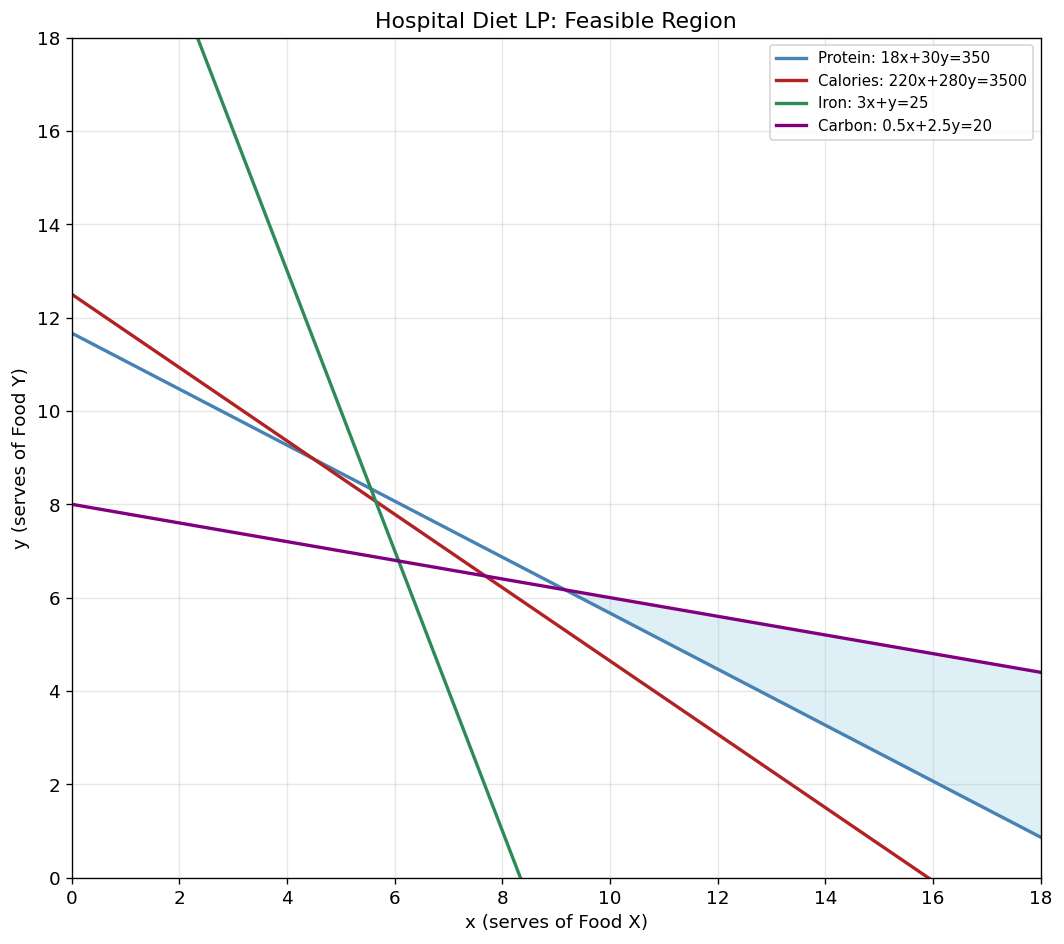

In [2]:
# B.1 — Plot all constraint lines
fig, ax = plt.subplots(figsize=(9, 8))

ax.plot(x_vals, protein_line(x_vals), "steelblue", lw=2, label="Protein: 18x+30y=350")
ax.plot(x_vals, calorie_line(x_vals), "firebrick", lw=2, label="Calories: 220x+280y=3500")
ax.plot(x_vals, iron_line(x_vals),    "seagreen",  lw=2, label="Iron: 3x+y=25")
ax.plot(x_vals, carbon_line(x_vals),  "purple",    lw=2, label="Carbon: 0.5x+2.5y=20")

# Shade feasible region (approximate)
y_grid = np.linspace(0, 20, 400)
xx, yy = np.meshgrid(x_vals, y_grid)
feasible = (
    (18*xx + 30*yy >= 350) &
    (220*xx + 280*yy >= 3500) &
    (3*xx + yy >= 25) &
    (0.5*xx + 2.5*yy <= 20) &
    (xx >= 0) & (yy >= 0)
)
ax.contourf(xx, yy, feasible.astype(float), levels=[0.5, 1.5], colors=["lightblue"], alpha=0.4)

ax.set_xlim(0, 18); ax.set_ylim(0, 18)
ax.set_xlabel("x (serves of Food X)"); ax.set_ylabel("y (serves of Food Y)")
ax.set_title("Hospital Diet LP: Feasible Region")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

---
## Part 3: Corner-Point Theorem (~10 min)

The minimum (or maximum) of a linear objective occurs at a **corner point** (vertex) of the feasible region.

**C.1** Find the corner points by solving pairs of constraints simultaneously.

Key intersections to check:
- Protein ∩ Iron: $18x + 30y = 350$ and $3x + y = 25$
- Protein ∩ Carbon: $18x + 30y = 350$ and $0.5x + 2.5y = 20$
- Calories ∩ Carbon: $220x + 280y = 3500$ and $0.5x + 2.5y = 20$
- Iron ∩ Carbon: $3x + y = 25$ and $0.5x + 2.5y = 20$

In [3]:
# C.1 — Find corner points by solving pairs of constraints
from numpy.linalg import solve as linsolve

def find_corner(A_mat, b_vec):
    'Solve 2×2 linear system A x = b.'
    try:
        sol = linsolve(np.array(A_mat, dtype=float), np.array(b_vec, dtype=float))
        return sol if all(s >= -1e-6 for s in sol) else None
    except np.linalg.LinAlgError:
        return None

# Constraint matrix rows: [coeff_x, coeff_y]
corners_raw = [
    find_corner([[18, 30], [3, 1]],      [350, 25]),      # protein ∩ iron
    find_corner([[18, 30], [0.5, 2.5]],  [350, 20]),      # protein ∩ carbon
    find_corner([[220, 280], [0.5, 2.5]],[3500, 20]),     # calories ∩ carbon
    find_corner([[3, 1], [0.5, 2.5]],    [25, 20]),       # iron ∩ carbon
    find_corner([[220, 280], [3, 1]],    [3500, 25]),     # calories ∩ iron
]

corners = [c for c in corners_raw if c is not None]

print(f"{'Corner (x,y)':25s} {'Z=2.5x+4y':>12} {'Feasible?':>12}")
print("-" * 52)
for c in corners:
    x, y = c
    Z = 2.5*x + 4*y
    # Check all constraints
    ok = (18*x + 30*y >= 349.9 and 220*x + 280*y >= 3499.9 and
          3*x + y >= 24.9 and 0.5*x + 2.5*y <= 20.1 and x >= -0.01 and y >= -0.01)
    print(f"({x:6.2f}, {y:6.2f})          Z = {Z:8.2f}     {'✓' if ok else '✗'}")

Corner (x,y)                 Z=2.5x+4y    Feasible?
----------------------------------------------------
(  5.56,   8.33)          Z =    47.22     ✗
(  9.17,   6.17)          Z =    47.58     ✓
(  7.68,   6.46)          Z =    45.06     ✗
(  6.07,   6.79)          Z =    42.32     ✗
(  5.65,   8.06)          Z =    46.37     ✗


Identify optimal corner.

In [4]:
# C.2 — Identify optimal corner
feasible_corners = []
for c in corners:
    x, y = c
    ok = (18*x + 30*y >= 349.9 and 220*x + 280*y >= 3499.9 and
          3*x + y >= 24.9 and 0.5*x + 2.5*y <= 20.1 and x >= -0.01 and y >= -0.01)
    if ok:
        feasible_corners.append((x, y, 2.5*x + 4*y))

if feasible_corners:
    best = min(feasible_corners, key=lambda c: c[2])
    print(f"Optimal solution: x* = {best[0]:.2f}, y* = {best[1]:.2f}")
    print(f"Minimum cost: Z* = ${best[2]:.2f} per patient per day")
else:
    print("No feasible corners found — check constraint formulation")

Optimal solution: x* = 9.17, y* = 6.17
Minimum cost: Z* = $47.58 per patient per day


Scipy LP verification.

In [5]:
# C.3 — Scipy LP verification
from scipy.optimize import linprog

# Minimise 2.5x + 4y
# Constraints: convert all to ≤ form (negate ≥ constraints)
c_obj = [2.5, 4.0]

A_ub = [
    [-18, -30],    # -protein ≤ -350
    [-220, -280],  # -calories ≤ -3500
    [-3, -1],      # -iron ≤ -25
    [0.5, 2.5],    # carbon ≤ 20
]
b_ub = [-350, -3500, -25, 20]

result = linprog(c_obj, A_ub=A_ub, b_ub=b_ub, bounds=[(0,None),(0,None)], method='highs')
print(f"scipy linprog result:")
print(f"  x* = {result.x[0]:.4f} serves of Food X")
print(f"  y* = {result.x[1]:.4f} serves of Food Y")
print(f"  Z* = ${result.fun:.4f} per patient per day")

scipy linprog result:
  x* = 9.1667 serves of Food X
  y* = 6.1667 serves of Food Y
  Z* = $47.5833 per patient per day


---
## Part 4 — Your Assigned LP Problem (45 minutes)

Your demonstrator will assign your group one of the three LP cards in the appendix at the end of this notebook (Card B, C, or D — several groups may share a card). Work through the full LP workflow for your assigned scenario:

1. Define decision variables (with units) and write the objective function.
2. Write all constraints, including non-negativity.
3. Graph the feasible region and find all feasible corner points.
4. Evaluate the objective at each corner point and state the optimal solution, identifying binding constraints.
5. Apply the sensitivity change stated on your card and find the new optimal solution.
6. Write a short (2–3 sentence) recommendation based on both results.

Reuse and adapt the code from the warmup above — the plotting, corner-point, and `linprog` cells all generalise directly to your assigned LP.

In [6]:
# Part 4 — adapt this scaffold for YOUR assigned LP card
# Replace every placeholder with your card's variables, objective, and constraints.

from numpy.linalg import solve as linsolve
from scipy.optimize import linprog

# --- Constraint lines (as functions of x for plotting y = f(x)) ---
def constraint_1(x):
    'Replace with your first constraint, e.g. a1*x + b1*y = c1  ->  y = (c1 - a1*x) / b1'
    return x  # placeholder

# --- Objective ---
def objective(x, y):
    'Replace with your objective, e.g. Z = c1*x + c2*y'
    return 0.0

# --- Corner points: solve pairs of binding constraints simultaneously ---
def find_corner(A_mat, b_vec):
    'Solve a 2x2 linear system A x = b for one candidate corner point.'
    try:
        sol = linsolve(np.array(A_mat, dtype=float), np.array(b_vec, dtype=float))
        return sol if all(s >= -1e-6 for s in sol) else None
    except np.linalg.LinAlgError:
        return None

# TODO: 1) plot your constraint lines and shade the feasible region (adapt Part 2 code)
# TODO: 2) list candidate corner points and check ALL constraints at each (adapt Part 3 code)
# TODO: 3) evaluate the objective at each feasible corner and identify the optimum
# TODO: 4) verify with scipy.optimize.linprog (negate the objective coefficients if maximising)
# TODO: 5) repeat steps 1-4 with your card's sensitivity change applied

---
## 📋 Your Assigned LP Problem and Solution

**Assigned card:** Card D

**Scenario (in your own words):** We are to find the maximum total biodiversity score availble in this wetland/forest restoration project.

```
WORKING:
Decision variables: x = wetland restoration (ha), y = forest restoration (ha)
Objective: Z = Maximum biodiversity score
Constraints:
1. Availble land = 80ha
2. Total budget = $240,000
3. Water availability = 180mL/year
4. Requirment of at least half as much forest area as wetland area
5. Threatened species requires a minimum of 18ha of wetland

Corner points and Z values:
(18,9) => Z=117
(18,54) => Z=252
(30,50) => Z=300
(40,40) => Z=320
(48,24) => Z=312
Optimal solution: (x*, y*) = (40,40), Z* = 320
Binding constraints: Availble land: 40+40=80 and budget: $160,000+$80,000 = $240,000

Sensitivity change: Budget changes to 2x + y _< 80
New optimal solution: (18,44) Z = 222
Recommendation: Allocate exactly 18ha of wetland resortation and 44ha to forest resoration.
```

---
## Part 5 — Class Discussion & Instructor Confirmation (15 minutes)

There is no peer verification this week — instead, your demonstrator will bring the class back together and call on groups to briefly present their assigned LP:

1. State your decision variables, objective, and constraints.
2. State your optimal solution and which constraints are binding.
3. State your sensitivity result and recommendation.

Your demonstrator will confirm whether each answer is correct and point out common errors. Update your write-up above with any corrections.

---
## Debrief (5 minutes)

Record one modelling insight and one issue your group will avoid next time.

```
DEBRIEF NOTES:
LP feature we understood well: ...
Correction or check that mattered: ...
One feasibility/sensitivity issue to avoid: ...
```

---
## 🎴 Assigned LP Problem Appendix

Your demonstrator will assign your group one of the three cards below. Read the scenario carefully — you formulate the decision variables, objective, and constraints yourself in Part 4.

### Card B — Crop Allocation: Wheat vs Chickpeas

A grain grower has 100 ha of arable land available for wheat ($x$ ha) and chickpeas ($y$ ha). Each hectare of wheat uses 3 ML of irrigation water and 2 person-days of labour; each hectare of chickpeas uses 2 ML of water and 4 person-days of labour. The property's water licence caps total irrigation at 240 ML, and 340 person-days of labour are available for the season. An agronomy adviser requires the chickpea area to be at least 1.5 times the wheat area (for soil nitrogen and disease-break benefits). An existing export contract requires at least 20 ha of wheat. Wheat returns a gross margin of $400/ha; chickpeas return $300/ha. **Maximise** total gross margin.

**Sensitivity:** If the water licence is cut to 210 ML, find the new optimal planting mix and gross margin.

### Card C — Hospital Staffing: Nurses vs Technicians

A hospital ward needs to roster nurse shifts ($x$) and technician shifts ($y$) for the week. At least 20 total shifts are needed for minimum ward coverage. Patient acuity requires a weighted coverage of at least 36 units, where each nurse shift contributes 2 acuity units and each technician shift contributes 1. Diagnostic and technical tasks require at least 24 technical-task units, with each nurse shift contributing 1 unit and each technician shift contributing 3 units. For safe supervision, technician shifts must not exceed twice the number of nurse shifts. Enterprise agreement rules cap nurse shifts at 18 per week. Each nurse shift costs 8 wage-index units and each technician shift costs 6 wage-index units. **Minimise** total wage-index cost.

**Sensitivity:** If a flu outbreak raises the acuity requirement to at least 40 units, find the new optimal roster and wage index.

### Card D — Biodiversity Corridor: Wetland vs Forest

A conservation authority is restoring degraded farmland into a wildlife corridor, combining wetland restoration ($x$ ha) and upland forest restoration ($y$ ha) on up to 80 ha of available land. Wetland restoration costs $4,000/ha and forest restoration costs $2,000/ha, drawn from a $240,000 budget. Each hectare of wetland requires 1 ML of water per year and each hectare of forest requires 3 ML; only 180 ML of water is available annually. Ecological guidelines require at least half as much forest area as wetland area, to buffer wetlands from surrounding agricultural land. A threatened waterbird species requires a minimum of 18 ha of wetland habitat. Wetland restoration scores 5 biodiversity points/ha; forest scores 3 points/ha. **Maximise** total biodiversity score.

**Sensitivity:** If the restoration budget is cut to $160,000, find the new optimal land allocation and biodiversity score.


---
## ✅ Submission Exercise — Batch 4 (due Tuesday 27 October, 11:59 pm)

**Submit via LMS. Covers Weeks 10–12 (hypothesis testing, trigonometry, linear programming).**

Work individually. Show all working. Write Python code where indicated.
Upload your **completed notebook (.ipynb)** to the LMS — do not submit screenshots.
        

In [ ]:

# Fill in your details before submitting
student_name   = "Your full name"
student_number = "Your student number (e.g. 23456789)"
print(f"Submission by: {student_name}  |  Student #{student_number}")



---
### Q1 — Hypothesis Testing (Week 10)

A regional water authority claims that following a public awareness campaign, **at least 85%** of households in a suburb comply with a summer water-restriction schedule (no outdoor watering between 9am–6pm). A council audit randomly inspects $n = 20$ households and finds that $x = 14$ comply.

Test whether the audit provides sufficient evidence to doubt the water authority's claim at the **5% significance level**.

**(a)** State $H_0$ and $H_1$ for a one-tailed test.



**Answer (a):**

...write your answer here...
        


**(b)** Let $X$ be the number of compliant households. State the distribution of $X$ under $H_0$, identifying $n$ and $p$. Explain why the claimed rate $p=0.85$ is used.



**Answer (b):**

...write your working here...
        


**(c)** Calculate the one-tailed $p$-value $P(X \le 14)$ under $X \sim \operatorname{Bin}(20, 0.85)$. You may build the lower-tail probability from these approximate components:

- $P(X=14) \approx 0.0454$
- $P(X=13) \approx 0.0160$
- $P(X=12) \approx 0.0046$
- $P(X\le11) \approx 0.0013$

Compare the $p$-value with $\alpha = 0.05$ and state your conclusion.



**Answer (c):**

...write your conclusion here...
        


**(d)** Verify the exact $p$-value by summing the Binomial PMF from $k=0$ to $14$ (e.g. using `math.comb` or `scipy.stats.binom`).


In [ ]:

# Q1d — exact p-value
from math import comb

# Your code here



---
### Q2 — Trigonometric Modelling (Week 11)

Daylight hours in a southern Australian city vary seasonally. The longest day has 14.5 hours (December 22) and the shortest has 9.5 hours (June 21).

**(a)** Find the amplitude $A$ and midline $D$.
        


**Answer (a):**

...write your working here...
        


**(b)** The period is 365 days. Find $B = 2\pi/365$.
        


**Answer (b):**

...write your answer here...
        


**(c)** Write the function $f(t)$ where $t$ = day of year, with $f(1) \approx 9.5$ (January 1 is near the shortest day). Use an appropriate phase shift.
        


**Answer (c):**

...write your function here...
        


**(d)** Plot $f(t)$ for one year and calculate the total daylight hours over the year using `numpy.trapz`.
        

In [ ]:

# Q2d — plot and integrate
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# Your code here




---
### Q3 — Linear Programming (Week 12)

A farmer grows wheat ($x$ ha) and canola ($y$ ha) on 200 ha. Constraints:
- Land: $x + y \leq 200$
- Water: $3x + 5y \leq 800$ (ML)
- Labour: $x + 2y \leq 300$ (days)
- Non-negativity: $x \geq 0$, $y \geq 0$

Profit: wheat $180/ha, canola $250/ha. **Maximise** $Z = 180x + 250y$.

**(a)** Graph the feasible region. Label each constraint line and shade the feasible region.
        


**Answer (a):** *(sketch or description)*

...write your description or attach a sketch here...
        


**(b)** Identify all corner points (intersections of constraint boundaries within the feasible region).
        


**Answer (b):**

...list corner points and show working here...
        


**(c)** Evaluate $Z$ at each corner point. State the optimal solution.
        


**Answer (c):**

...write your working and conclusion here...
        


**(d)** Verify your answer using `scipy.optimize.linprog`. (Note: `linprog` minimises — negate the objective to maximise.)
        

In [ ]:

# Q3d — linprog verification
from scipy.optimize import linprog

# Your code here

